# Assignment: Research Design & Experiment
## Predicting Titanic Passenger Survival

**Research Question:** Can passenger characteristics such as class, age, sex, family relationships, fare, and embarkation point be used to predict Titanic survival?

This notebook cleans the provided Titanic dataset, engineers useful features, trains Linear Regression and Logistic Regression models, and evaluates their performance.

## Literature Review — 4 Sources

1. **Kaggle — Titanic: Machine Learning from Disaster.** The Titanic dataset is a widely used machine-learning classification problem. It contains passenger information such as class, sex, age, fare, and family relationships that can be used to study survival.

2. **scikit-learn — Logistic Regression.** Logistic Regression estimates the probability of a binary outcome and is therefore appropriate for predicting the `Survived` target. It also provides interpretable classification probabilities.

3. **scikit-learn — Linear Regression.** Linear Regression predicts a continuous numerical value from input features. Here it is used as a simple baseline, with its output converted to a survival class using a 0.5 threshold.

4. **Seaborn — Titanic Dataset.** The Titanic dataset is commonly used for statistical analysis and visualization. Variables including sex, passenger class, age, and fare provide useful predictors for survival analysis.

## Methodology

**Dataset:** `output_train.csv`, 889 rows and 13 columns. The target is `Survived` (0/1). Main predictors are `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, and `Embarked`.

**Cleaning:** Remove the extra index column, exclude identifiers/high-cardinality text fields from modeling, inspect missing values, median-impute numeric values, most-frequent-impute categorical values, and one-hot encode categorical variables.

**Feature engineering:** Create `FamilySize = SibSp + Parch + 1` and `IsAlone`, then use these with passenger class, age, family counts, fare, sex, and embarkation.

**Models:** Linear Regression is used as a baseline numerical model. Logistic Regression is used as the main classification model because the target is binary.

**Metrics:** Linear Regression uses MAE, MSE, R², and thresholded accuracy. Logistic Regression uses accuracy, precision, recall, and F1-score.

In [8]:
#Create experiment.ipynb

In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

df = pd.read_csv("output_train.csv")
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (889, 13)


,Unnamed: 0,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Sex_num
0,0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,0
1,1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,1
2,2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,1
3,3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,1
4,4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,0


## 1. Dataset Inspection

In [ ]:
print("Columns:")
print(df.columns.tolist())
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing"))
print("\nTarget distribution:")
display(df["Survived"].value_counts().to_frame("Count"))


## 2. Data Cleaning and Feature Engineering

In [ ]:
data = df.copy()

# Remove accidental index
if "Unnamed: 0" in data.columns:
    data = data.drop(columns=["Unnamed: 0"])

# Engineer features
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

features = [
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare",
    "Embarked", "FamilySize", "IsAlone"
]
X = data[features]
y = data["Survived"]

print("Selected features:", features)
print("Prepared shape:", X.shape)
display(X.head())


In [ ]:
print("Missing values in selected features:")
display(X.isnull().sum().to_frame("Missing"))

print("Engineered feature summary:")
display(data[["FamilySize", "IsAlone"]].describe())


## 3. Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training:", X_train.shape)
print("Testing :", X_test.shape)


## 4. Preprocessing

In [ ]:
numeric_features = ["Pclass","Age","SibSp","Parch","Fare","FamilySize","IsAlone"]
categorical_features = ["Sex","Embarked"]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline ready.")


## 5. Model 1 — Linear Regression

In [ ]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)
linear_class = (linear_pred >= 0.5).astype(int)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_mse = mean_squared_error(y_test, linear_pred)
linear_r2 = r2_score(y_test, linear_pred)
linear_accuracy = accuracy_score(y_test, linear_class)

print("Linear Regression")
print("MAE      :", round(linear_mae, 4))
print("MSE      :", round(linear_mse, 4))
print("R2       :", round(linear_r2, 4))
print("Accuracy :", round(linear_accuracy, 4))


## 6. Model 2 — Logistic Regression

In [ ]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_model.fit(X_train, y_train)
logistic_pred = logistic_model.predict(X_test)

logistic_accuracy = accuracy_score(y_test, logistic_pred)
logistic_precision = precision_score(y_test, logistic_pred, zero_division=0)
logistic_recall = recall_score(y_test, logistic_pred, zero_division=0)
logistic_f1 = f1_score(y_test, logistic_pred, zero_division=0)

print("Logistic Regression")
print("Accuracy  :", round(logistic_accuracy, 4))
print("Precision :", round(logistic_precision, 4))
print("Recall    :", round(logistic_recall, 4))
print("F1-score  :", round(logistic_f1, 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, logistic_pred))


## 7. Model Comparison

In [ ]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Logistic Regression"],
    "Accuracy": [linear_accuracy, logistic_accuracy],
    "MAE": [linear_mae, np.nan],
    "MSE": [linear_mse, np.nan],
    "R2": [linear_r2, np.nan],
    "Precision": [np.nan, logistic_precision],
    "Recall": [np.nan, logistic_recall],
    "F1": [np.nan, logistic_f1]
})
display(results.round(4))


## 8. Findings and Future Improvements

The experiment shows that passenger characteristics can be used to predict Titanic survival. Logistic Regression is the more suitable of the two models because the target variable is binary and the model is specifically designed for classification. Linear Regression provides a useful baseline, but its continuous output is not naturally restricted to the two survival classes. The engineered `FamilySize` and `IsAlone` features add information about passengers' family circumstances. With more time, I would compare Random Forest, Gradient Boosting, and Support Vector Machine models. I would also use cross-validation, hyperparameter tuning, and additional feature engineering such as extracting passenger titles from `Name`.

## References

- Kaggle — *Titanic: Machine Learning from Disaster*
- scikit-learn — *LogisticRegression*
- scikit-learn — *LinearRegression*
- Seaborn — *Titanic dataset*

### Suggested incremental Git commits

```bash
git checkout -b experiment
git add .
git commit -m "Add research design and literature review"

git add experiment.ipynb
git commit -m "Add Titanic experiment notebook"

git add experiment.ipynb
git commit -m "Clean dataset and engineer features"

git add experiment.ipynb
git commit -m "Train and evaluate linear and logistic regression"

git push -u origin experiment
```

Then open a Pull Request from **experiment → main**, merge it, and push the updated repository.

In [ ]:
#Create Chart 1 — Model Accuracy
import os
import matplotlib.pyplot as plt

# Create the figures folder
os.makedirs("figures", exist_ok=True)

# Compare the accuracy of both models
models = ["Linear Regression", "Logistic Regression"]
accuracies = accuracies = [81.46, 82.02]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies)

plt.title("Comparison of Model Accuracy")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("figures/chart1.png", dpi=300)
plt.show()

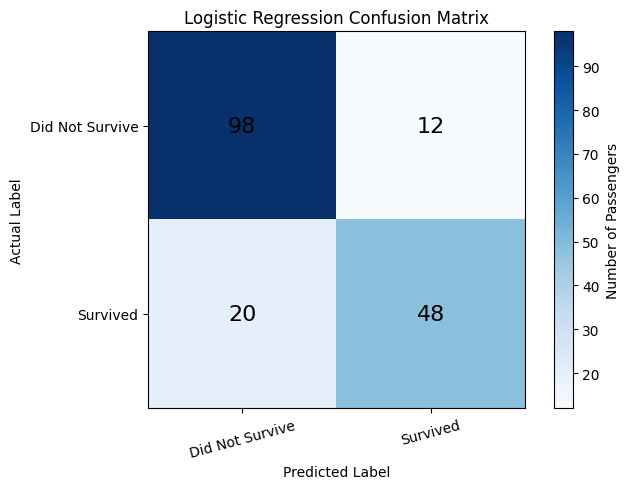

In [36]:

import os
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Create the figures folder if it does not exist
os.makedirs("figures", exist_ok=True)

# Calculate confusion matrix
cm = confusion_matrix(y_test, logistic_pred)

# Draw the chart
fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(cm, cmap="Blues")

ax.set_title("Logistic Regression Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")

ax.set_xticks([0, 1])
ax.set_xticklabels(["Did Not Survive", "Survived"], rotation=15)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Did Not Survive", "Survived"])

# Display the values
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]),
                ha="center", va="center", fontsize=16)

fig.colorbar(im, ax=ax, label="Number of Passengers")
fig.tight_layout()

# Save and display
fig.savefig("figures/chart2.png", dpi=300, bbox_inches="tight")
plt.show()
